# MOP 3231 · Task 3 — Midterm Project

**Student:** aselmuratbek  
**SEED:** 2534  
**Task:** Binary classification — predict term deposit subscription (`y`)  
**Metric:** ROC-AUC, Average Precision (target imbalanced: 11.27% positives)

In [1]:
import sys, platform, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve,
                             precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 2534
BASE = "/Users/aselmuratbek/Desktop/task_3_Assel_ML/aselmuratbek_ML_task_3"

print("Python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)

train = pd.read_csv(os.path.join(BASE, "data/train.csv"))
test  = pd.read_csv(os.path.join(BASE, "data/test.csv"))
print("train shape:", train.shape)
print("test  shape:", test.shape)
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))
train.head()

Python : 3.12.7
numpy  : 1.26.4
pandas : 2.2.2
train shape: (32940, 22)
test  shape: (8236, 20)
columns only in train: ['duration', 'y']


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Stage 1 · Frame the problem

**Business question.** Portuguese bank phones clients to sell a term deposit. Capacity: 10 % of the list per wave. Rank clients so the top 10 % who get called are as likely as possible to say yes. Scoring is done **before** the call.

**Metric.** Only 11.27 % are "yes" → accuracy misleads (88.73% for all-"no"). Use **ROC-AUC** and **Average Precision**; **precision@10%** for the decision.

**train vs test columns.** `test.csv` lacks `y` (target withheld) and `duration` (call duration — known only *after* call → data leakage). Pipeline built **without `duration`**.

y counts: {'no': 29229, 'yes': 3711}
majority accuracy: 0.8873
   column  unknown  unknown_%  nonexistent
  default     6871      20.86            0
education     1401       4.25            0
  housing      794       2.41            0
     loan      794       2.41            0
      job      275       0.83            0
  marital       64       0.19            0
 poutcome        0       0.00        28446

pdays == 999: 31694 (96.2%)


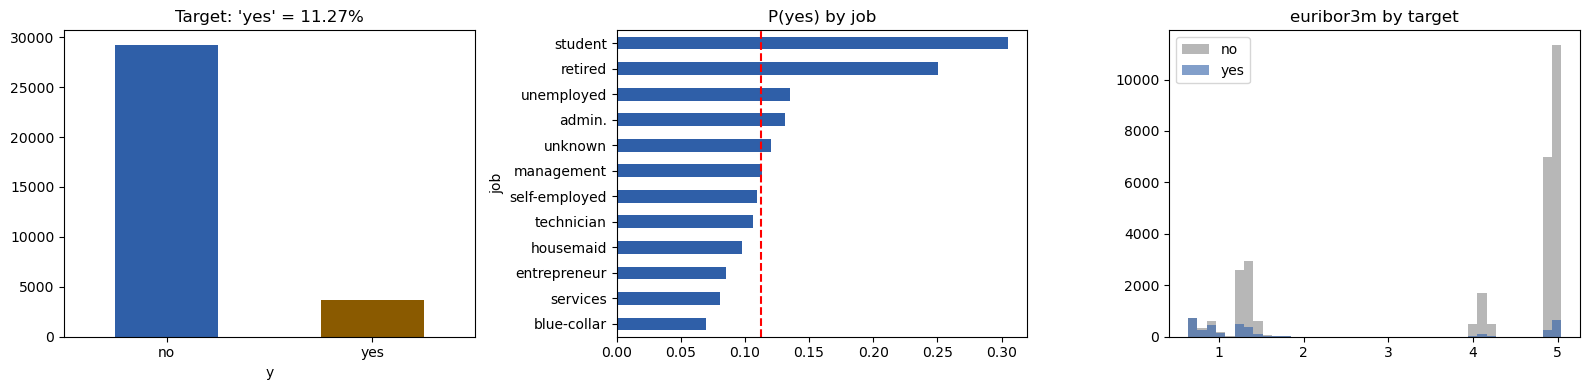


Observation: majority = 88.73%, recall on 'yes' = 0
P(yes) by job: 0.070 (blue-collar) to 0.305 (student)


In [2]:
# Stage 2 · EDA
counts = train["y"].value_counts()
share  = train["y"].value_counts(normalize=True).round(4)
print("y counts:", dict(counts))
print("majority accuracy:", round(share["no"], 4))

cat_cols = train.select_dtypes(include="object").columns.drop("y")
rows = []
for col in cat_cols:
    n_unk = (train[col] == "unknown").sum()
    n_non = (train[col] == "nonexistent").sum()
    if n_unk or n_non:
        rows.append({"column": col, "unknown": n_unk,
                     "unknown_%": round(100 * n_unk / len(train), 2),
                     "nonexistent": n_non})
print(pd.DataFrame(rows).sort_values("unknown_%", ascending=False).to_string(index=False))
print("\npdays == 999:", (train["pdays"] == 999).sum(),
      f"({100*(train['pdays']==999).mean():.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
counts.plot(kind="bar", ax=axes[0], rot=0, color=["#2f5fa8", "#8a5a00"])
axes[0].set_title(f"Target: 'yes' = {share['yes']*100:.2f}%")

job_rate = train.assign(yb=(train["y"]=="yes").astype(int)).groupby("job")["yb"].mean().sort_values()
job_rate.plot(kind="barh", ax=axes[1], color="#2f5fa8")
axes[1].axvline(share["yes"], color="red", ls="--")
axes[1].set_title("P(yes) by job")

for lbl, c in [("no", "#888"), ("yes", "#2f5fa8")]:
    axes[2].hist(train.loc[train["y"]==lbl, "euribor3m"], bins=40, alpha=0.6, label=lbl, color=c)
axes[2].set_title("euribor3m by target"); axes[2].legend()
plt.tight_layout(); plt.show()

print(f"\nObservation: majority = {share['no']:.2%}, recall on 'yes' = 0")
print(f"P(yes) by job: {job_rate.min():.3f} ({job_rate.idxmin()}) to {job_rate.max():.3f} ({job_rate.idxmax()})")

In [3]:
# Stage 3 · Hold-out + CV · Stage 4 · Pipeline
FEATURES = [c for c in train.columns if c not in ("id", "y", "duration")]
X = train[FEATURES]
y = (train["y"] == "yes").astype(int).values

X_tr, X_ho, y_tr, y_ho = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("CV part:", X_tr.shape, "| hold-out:", X_ho.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include="object").columns.tolist()

num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("sc",  StandardScaler())])
cat_pipe = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                     ("oh",  OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocess = ColumnTransformer([("num", num_pipe, num_cols),
                                ("cat", cat_pipe, cat_cols)])
print("Pipeline ready.")

CV part: (26352, 19) | hold-out: (6588, 19)
Pipeline ready.


In [4]:
# Stage 5+6 · Baselines + model comparison
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

scoring = {"roc_auc": "roc_auc", "avg_prec": "average_precision"}

def evaluate(name, model):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    res = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=1)
    return {"model": name,
            "roc_auc": res["test_roc_auc"].mean(),
            "roc_std": res["test_roc_auc"].std(),
            "avg_prec": res["test_avg_prec"].mean(),
            "ap_std": res["test_avg_prec"].std()}

rows = [
    evaluate("Majority (Dummy)",  DummyClassifier(strategy="most_frequent")),
    evaluate("LogReg (baseline)", LogisticRegression(max_iter=2000, random_state=SEED)),
    evaluate("KNN (k=15)",        KNeighborsClassifier(n_neighbors=15)),
    evaluate("DecisionTree (d=8)",DecisionTreeClassifier(max_depth=8, random_state=SEED)),
    evaluate("RandomForest (300)",RandomForestClassifier(n_estimators=300, random_state=SEED)),
    evaluate("SVM (RBF)",         SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED)),
    evaluate("LogReg (balanced)", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    evaluate("RF (balanced)",     RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED)),
]
results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
pd.set_option("display.float_format", "{:.4f}".format)
print("=== 5-fold CV (seed=2534) ===")
print(results.to_string(index=False))

=== 5-fold CV (seed=2534) ===
             model  roc_auc  roc_std  avg_prec  ap_std
 LogReg (balanced)   0.7913   0.0024    0.4485  0.0062
 LogReg (baseline)   0.7906   0.0020    0.4532  0.0062
     RF (balanced)   0.7765   0.0040    0.4129  0.0132
RandomForest (300)   0.7765   0.0039    0.4159  0.0121
DecisionTree (d=8)   0.7705   0.0053    0.3997  0.0115
        KNN (k=15)   0.7628   0.0044    0.3985  0.0130
         SVM (RBF)   0.6993   0.0067    0.4058  0.0111
  Majority (Dummy)   0.5000   0.0000    0.1127  0.0001


ROC-AUC: 0.8005  |  Average Precision: 0.4508


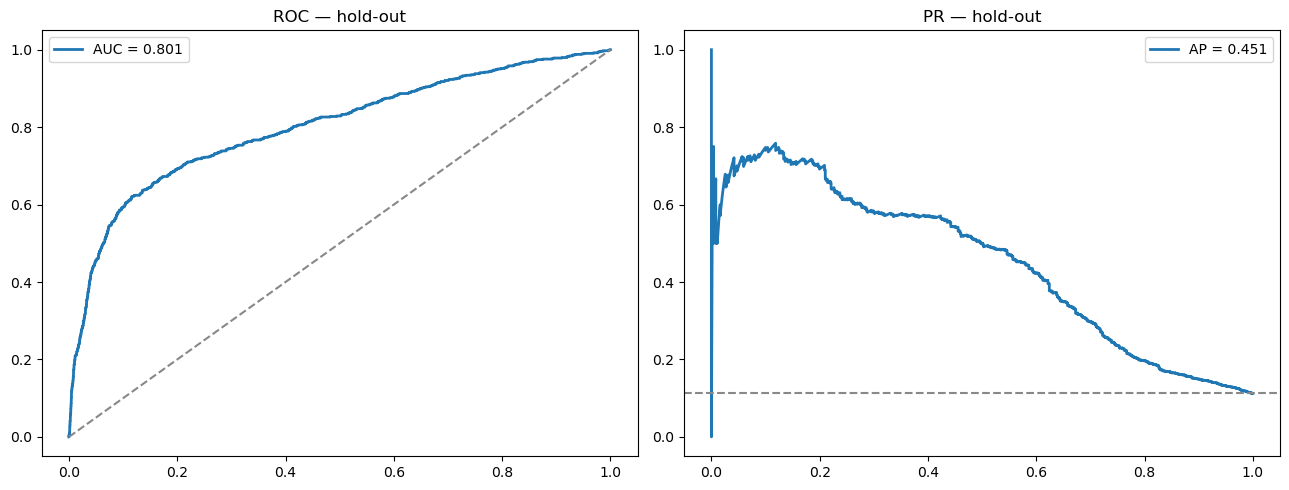


Top 658 called | Precision@10%: 0.5198 | Recall@10%: 0.4609 | Lift: x4.61
Among 658 called: 342 subscribe -> 52.0% success
Random would give 11.3% -> lift x4.61


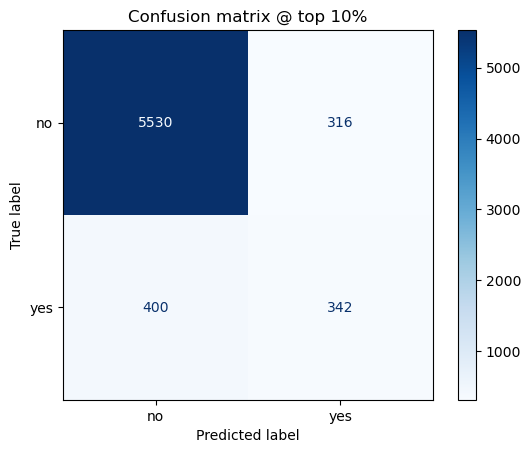

In [5]:
# Stage 7 · Final evaluation on hold-out
final_pipe = Pipeline([("prep", preprocess),
                       ("model", LogisticRegression(max_iter=2000, random_state=SEED))])
final_pipe.fit(X_tr, y_tr)
y_score_ho = final_pipe.predict_proba(X_ho)[:, 1]

roc_auc = roc_auc_score(y_ho, y_score_ho)
ap      = average_precision_score(y_ho, y_score_ho)
print(f"ROC-AUC: {roc_auc:.4f}  |  Average Precision: {ap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fpr, tpr, _ = roc_curve(y_ho, y_score_ho)
axes[0].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0,1],[0,1],"--", color="#888"); axes[0].set_title("ROC — hold-out"); axes[0].legend()

prec, rec, _ = precision_recall_curve(y_ho, y_score_ho)
axes[1].plot(rec, prec, lw=2, label=f"AP = {ap:.3f}")
axes[1].axhline(y_ho.mean(), ls="--", color="#888"); axes[1].set_title("PR — hold-out"); axes[1].legend()
plt.tight_layout(); plt.show()

K = int(0.10 * len(y_ho))
thr = np.sort(y_score_ho)[-K]
y_pred_cap = (y_score_ho >= thr).astype(int)
prec_cap = precision_score(y_ho, y_pred_cap)
rec_cap  = recall_score(y_ho, y_pred_cap)
hits = ((y_pred_cap==1)&(y_ho==1)).sum()
base = y_ho.mean(); lift = prec_cap/base

print(f"\nTop {K} called | Precision@10%: {prec_cap:.4f} | Recall@10%: {rec_cap:.4f} | Lift: x{lift:.2f}")
print(f"Among {K} called: {hits} subscribe -> {prec_cap*100:.1f}% success")
print(f"Random would give {base*100:.1f}% -> lift x{lift:.2f}")

cm = confusion_matrix(y_ho, y_pred_cap)
ConfusionMatrixDisplay(cm, display_labels=["no","yes"]).plot(cmap="Blues")
plt.title("Confusion matrix @ top 10%"); plt.show()